In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/measures_v2.csv")

print("Dataset loaded!")
print("Shape:", df.shape)

Dataset loaded!
Shape: (1330816, 13)


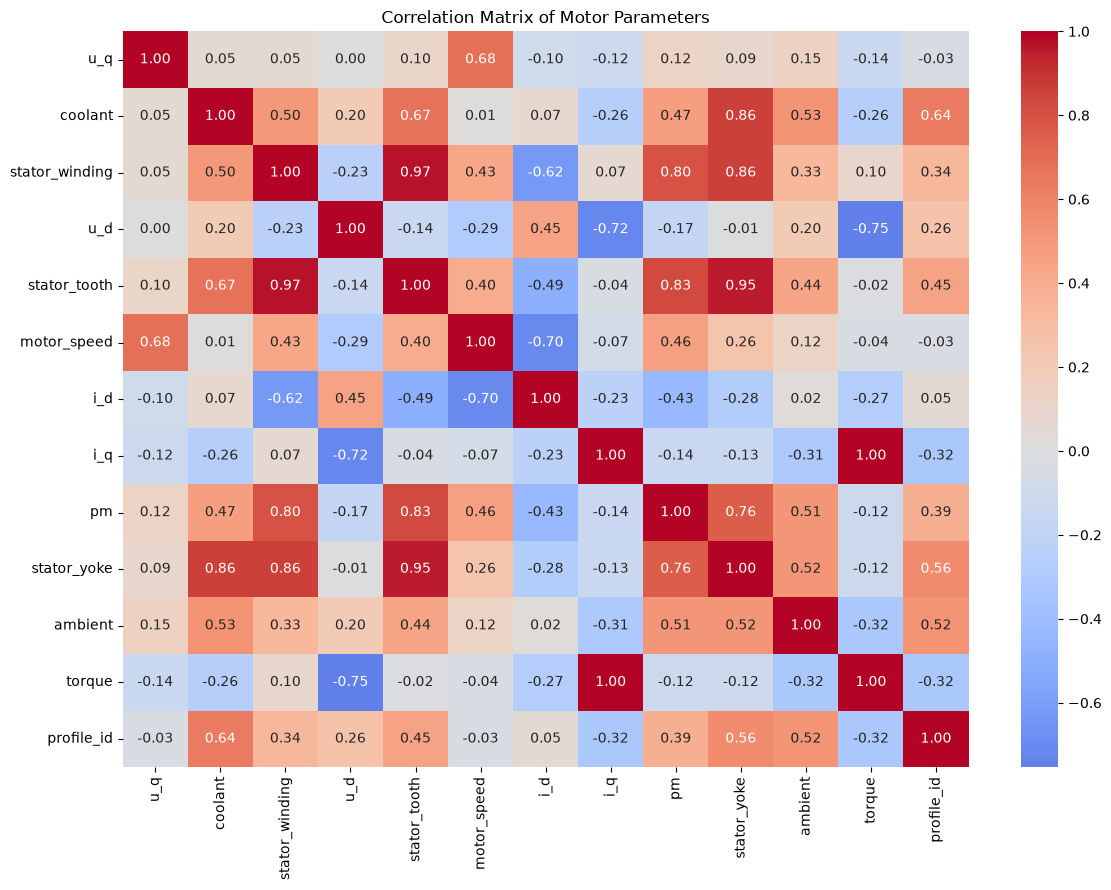

In [2]:
plt.figure(figsize=(12, 9))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Motor Parameters")
plt.tight_layout()

plt.savefig("../graphs/correlation_heatmap.png", dpi=300)

plt.show()

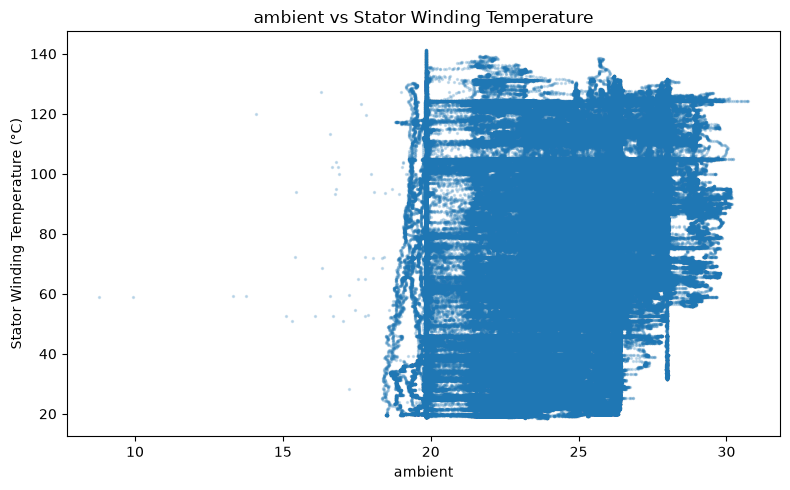

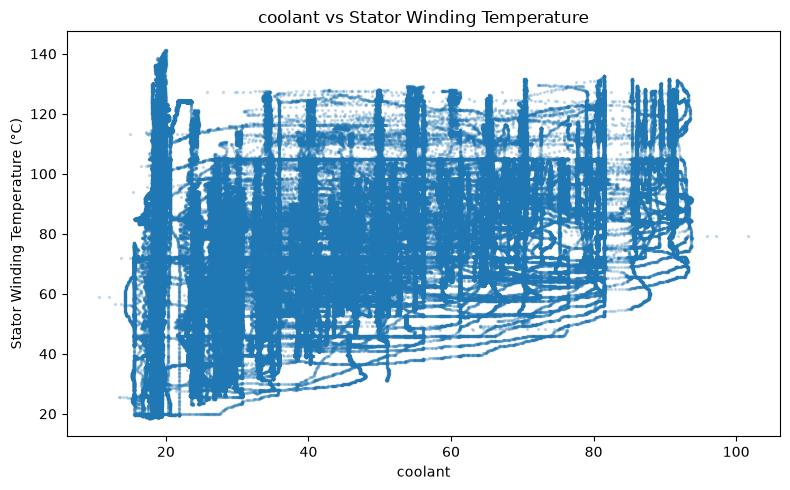

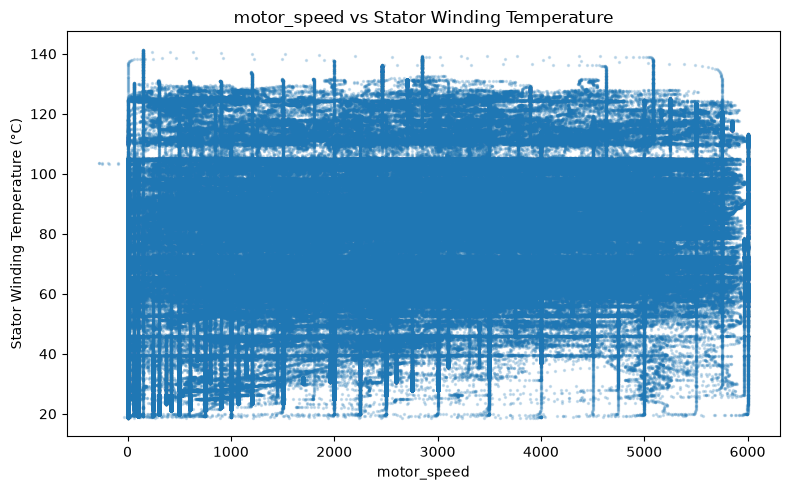

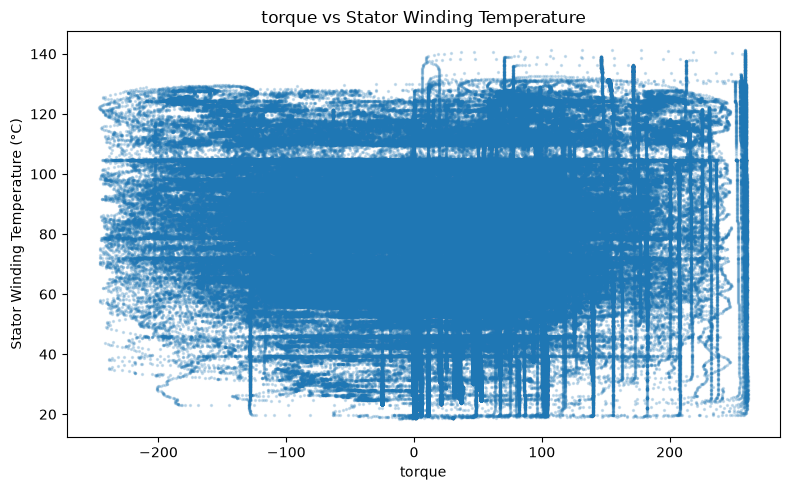

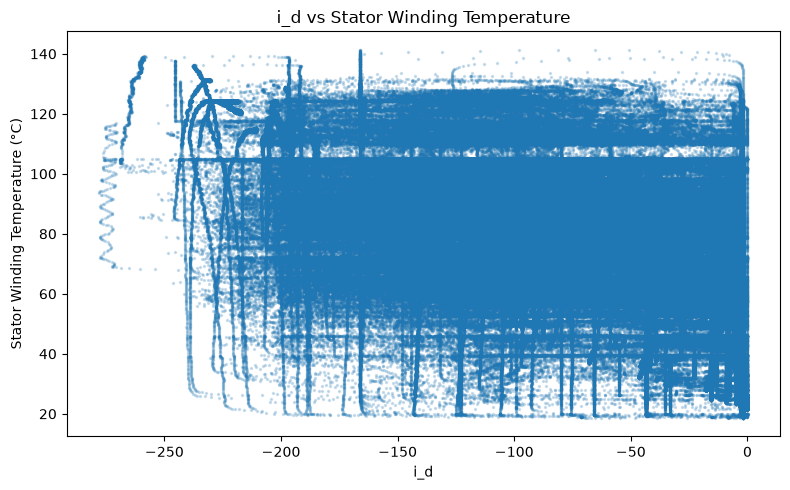

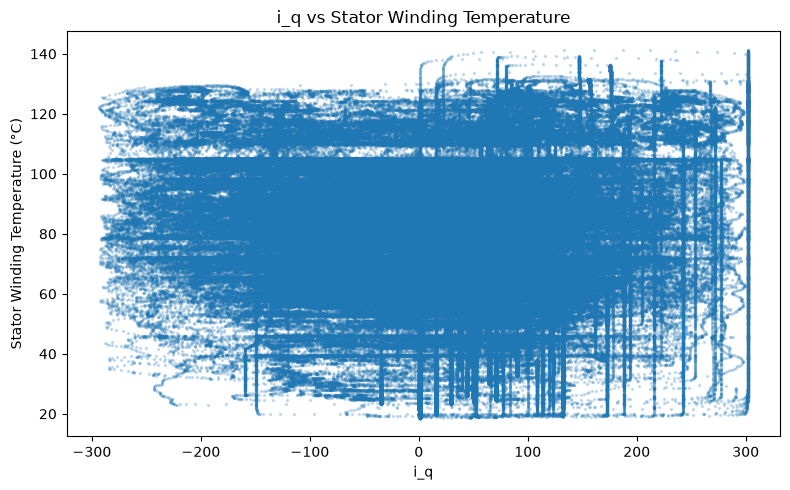

In [3]:
features_to_plot = [
    "ambient",
    "coolant",
    "motor_speed",
    "torque",
    "i_d",
    "i_q"
]

for feature in features_to_plot:
    
    plt.figure(figsize=(8, 5))
    
    plt.scatter(
        df[feature],
        df["stator_winding"],
        s=2,
        alpha=0.2
    )
    
    plt.xlabel(feature)
    plt.ylabel("Stator Winding Temperature (°C)")
    plt.title(f"{feature} vs Stator Winding Temperature")
    
    plt.tight_layout()
    plt.savefig(
        f"../graphs/{feature}_vs_stator_winding.png",
        dpi=300
    )
    
    plt.show()

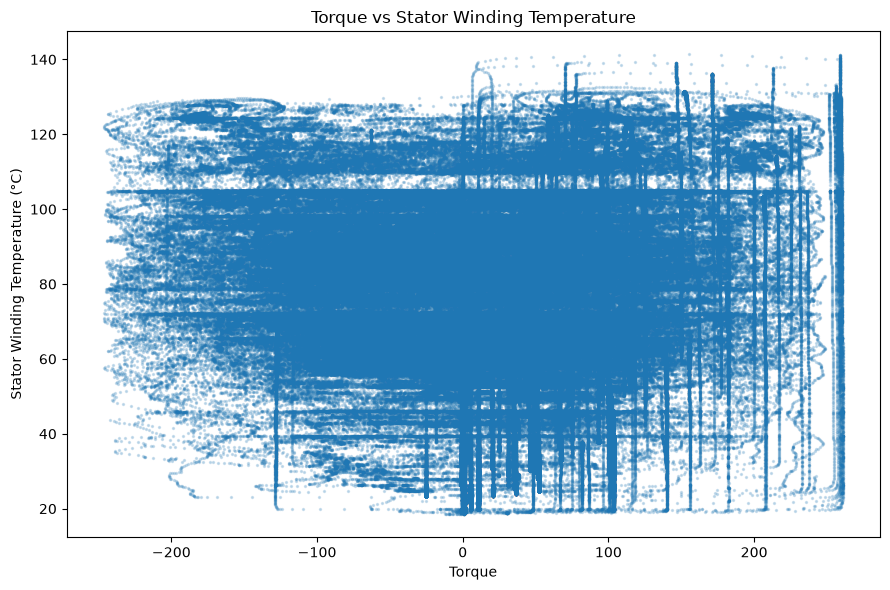

In [4]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["torque"],
    df["stator_winding"],
    s=2,
    alpha=0.2
)

plt.xlabel("Torque")
plt.ylabel("Stator Winding Temperature (°C)")
plt.title("Torque vs Stator Winding Temperature")

plt.tight_layout()

plt.savefig("../graphs/torque_vs_stator_winding.png", dpi=300)

plt.show()

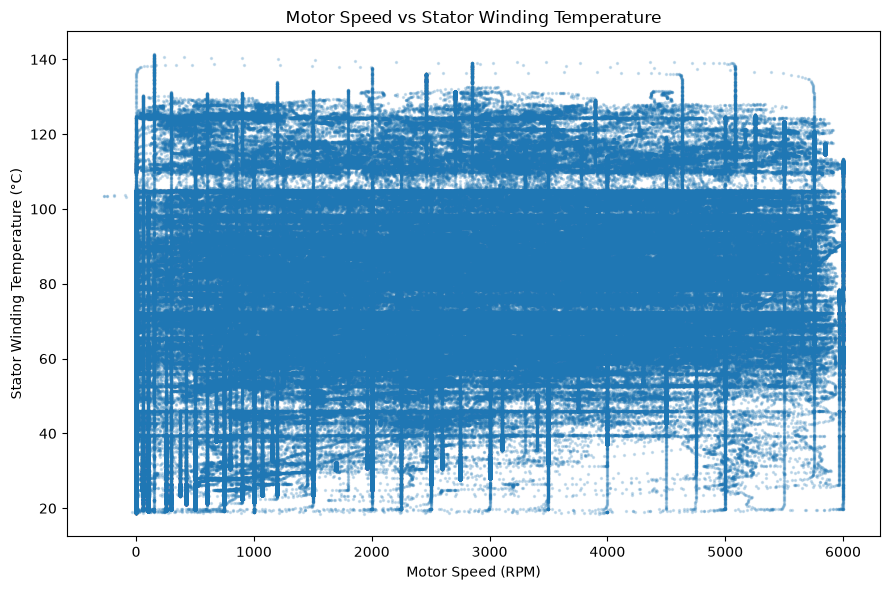

In [5]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["motor_speed"],
    df["stator_winding"],
    s=2,
    alpha=0.2
)

plt.xlabel("Motor Speed (RPM)")
plt.ylabel("Stator Winding Temperature (°C)")
plt.title("Motor Speed vs Stator Winding Temperature")

plt.tight_layout()

plt.savefig("../graphs/motor_speed_vs_stator_winding.png", dpi=300)

plt.show()

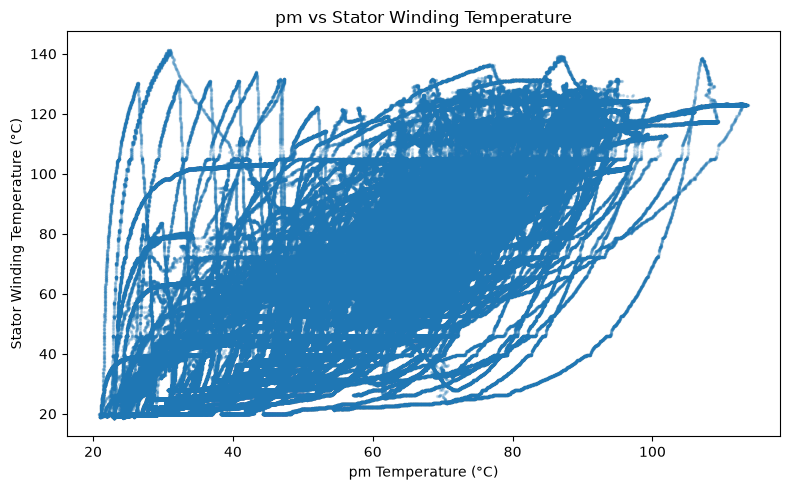

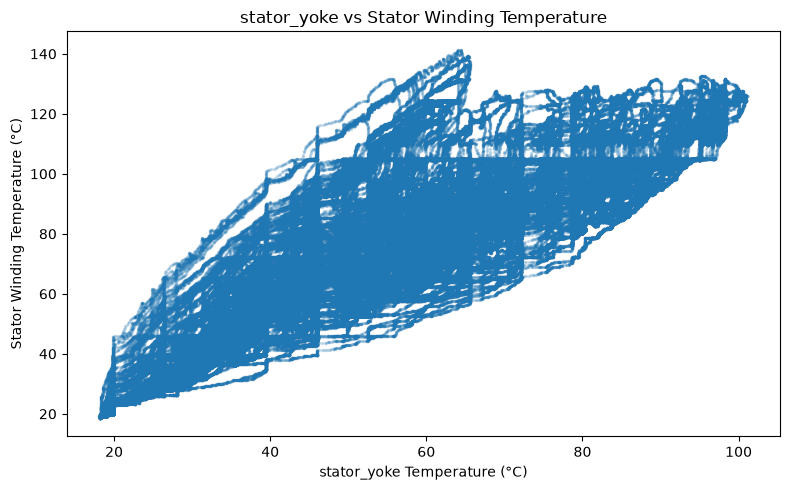

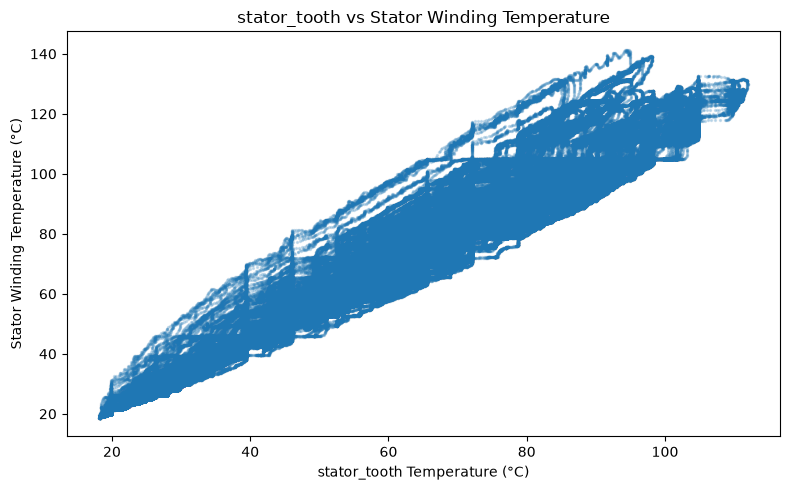

In [6]:
temperature_features = [
    "pm",
    "stator_yoke",
    "stator_tooth"
]

for feature in temperature_features:
    
    plt.figure(figsize=(8, 5))
    
    plt.scatter(
        df[feature],
        df["stator_winding"],
        s=2,
        alpha=0.2
    )
    
    plt.xlabel(f"{feature} Temperature (°C)")
    plt.ylabel("Stator Winding Temperature (°C)")
    plt.title(f"{feature} vs Stator Winding Temperature")
    
    plt.tight_layout()
    
    plt.savefig(
        f"../graphs/{feature}_vs_stator_winding.png",
        dpi=300
    )
    
    plt.show()

In [7]:
print("Rows per profile:")
print(df["profile_id"].value_counts().sort_index())

print("\nNumber of profiles:")
print(df["profile_id"].nunique())

print("\nFirst 20 profile IDs:")
print(df["profile_id"].head(20).tolist())

print("\nProfile transitions:")
print((df["profile_id"] != df["profile_id"].shift()).sum())

Rows per profile:
profile_id
2     19357
3     19248
4     33424
5     14788
6     40388
      ...  
76    22188
78     8445
79    31154
80    23824
81    17672
Name: count, Length: 69, dtype: int64

Number of profiles:
69

First 20 profile IDs:
[17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17]

Profile transitions:
69


In [8]:
profile_sizes = df.groupby("profile_id").size()

print("Minimum observations per profile:", profile_sizes.min())
print("Maximum observations per profile:", profile_sizes.max())
print("Mean observations per profile:", profile_sizes.mean())
print("Median observations per profile:", profile_sizes.median())

Minimum observations per profile: 2176
Maximum observations per profile: 43971
Mean observations per profile: 19287.1884057971
Median observations per profile: 17142.0


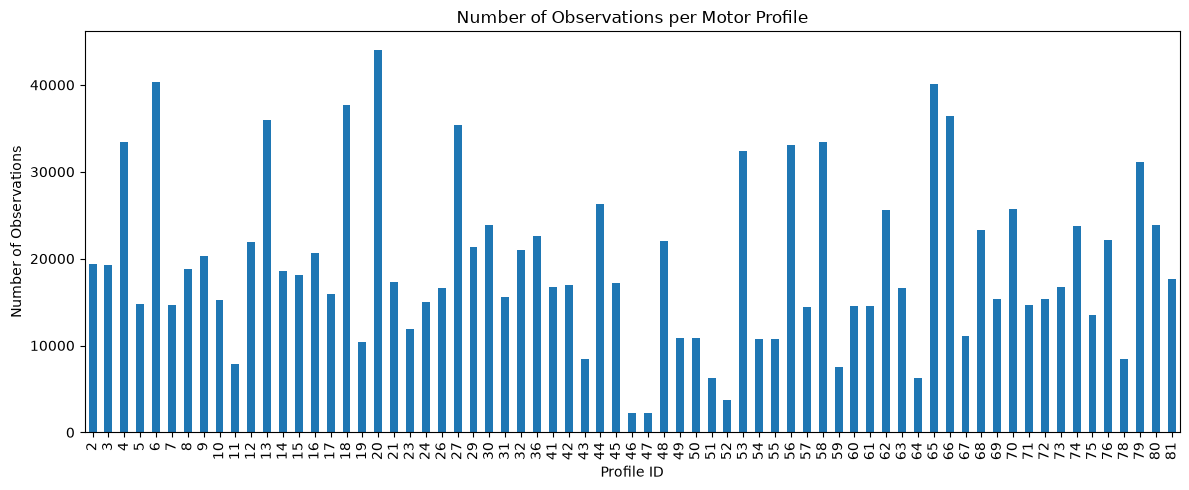

In [9]:
plt.figure(figsize=(12, 5))

profile_sizes.sort_index().plot(kind="bar")

plt.xlabel("Profile ID")
plt.ylabel("Number of Observations")
plt.title("Number of Observations per Motor Profile")

plt.tight_layout()
plt.savefig("../graphs/profile_observation_counts.png", dpi=300)

plt.show()